In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Unzip normalized dataset
import os
import shutil

zip_DIR = '/content/drive/MyDrive/tcga_slides_224_zip'
temp_DIR = '/content/temp'

for file in os.listdir(zip_DIR):
    if file.endswith('.zip'):
        zip_file_path = os.path.join(zip_DIR, file)
    else:
        continue

    shutil.unpack_archive(zip_file_path, temp_DIR)

In [ ]:
import pandas as pd
import shutil
import os
from tqdm import tqdm

# Unzip slide tiles
zip_DIR = '/content/temp/zips'
dataset_DIR = '/content/datasets'

for file in tqdm(os.listdir(zip_DIR)):
    if file.endswith('.zip'):
        zip_file_path = os.path.join(zip_DIR, file)
    else:
        continue

    shutil.unpack_archive(zip_file_path, dataset_DIR)
    os.remove(zip_file_path)

100%|██████████| 789/789 [12:12<00:00,  1.08it/s]


# Load UNI2-h model

In [ ]:
import torch
import timm
from timm.data import resolve_data_config
from timm.data.transforms_factory import create_transform
from timm.layers import SwiGLUPacked
from huggingface_hub import login

login()  # login with your User Access Token, found at https://huggingface.co/settings/tokens

# pretrained=True needed to load UNI2-h weights (and download weights for the first time)
timm_kwargs = {
            'img_size': 224,
            'patch_size': 14,
            'depth': 24,
            'num_heads': 24,
            'init_values': 1e-5,
            'embed_dim': 1536,
            'mlp_ratio': 2.66667*2,
            'num_classes': 0,
            'no_embed_class': True,
            'mlp_layer': SwiGLUPacked,
            'act_layer': torch.nn.SiLU,
            'reg_tokens': 8,
            'dynamic_img_size': True
        }
model = timm.create_model("hf-hub:MahmoodLab/UNI2-h", pretrained=True, **timm_kwargs)
transform = create_transform(**resolve_data_config(model.pretrained_cfg, model=model))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()

config.json:   0%|          | 0.00/587 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/2.73G [00:00<?, ?B/s]

VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 1536, kernel_size=(14, 14), stride=(14, 14))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((1536,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=1536, out_features=4608, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=1536, out_features=1536, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): LayerScale()
      (drop_path1): Identity()
      (norm2): LayerNorm((1536,), eps=1e-06, elementwise_affine=True)
      (mlp): GluMlp(
        (fc1): Linear(in_features=1536, out_features=8192, bias=True)
        (act): SiLU()
        (drop1): Dropout(p=0.0, inplace=False)
    

# Dataset and Dataloader (with rotation optional augmentation)

In [ ]:
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader


class Uni2Dataset(Dataset):
    def __init__(self, root_dir, transform, num_rotations=0):
        self.samples = []

        for patient in os.listdir(root_dir):
            pat_path = os.path.join(root_dir, patient)
            if not os.path.isdir(pat_path):
                continue
            for image in os.listdir(pat_path):
                if image.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
                    self.samples.append((os.path.join(pat_path, image),
                                        patient, image))

        self.transform = transform
        self.num_rotations = num_rotations

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        img_path, patient, img_name = self.samples[idx]
        mask = Image.open(img_path).convert("RGB")
        img = self.transform(mask)
        # Optional rotation
        img = torch.rot90(img, k=self.num_rotations, dims=(1,2))
        return img, patient, img_name

In [ ]:
# No rotation config
DATA_DIR = "datasets"            # Root folder: class/patient/img.jpg
NUM_ROTATIONS = 0                # Number of times to rotate the image by 90 degrees
BATCH_SIZE = 256
NUM_WORKERS = 4

dataset_original = Uni2Dataset(DATA_DIR, transform, num_rotations=NUM_ROTATIONS)
dataloader_original = DataLoader(dataset_original, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

In [ ]:
# 270 deg rotation config
DATA_DIR = "datasets"            # Root folder: class/patient/img.jpg
NUM_ROTATIONS = 3                # Number of times to rotate the image by 90 degrees
BATCH_SIZE = 256
NUM_WORKERS = 4

dataset_rot270 = Uni2Dataset(DATA_DIR, transform, num_rotations=NUM_ROTATIONS)
dataloader_rot270 = DataLoader(dataset_rot270, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)

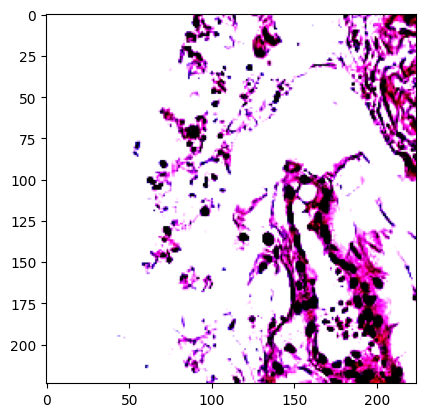

In [ ]:
import matplotlib.pyplot as plt

# Show original image
mass_img, patient, img_name = dataset_original[0]
plt.imshow(mass_img.permute(1, 2, 0))

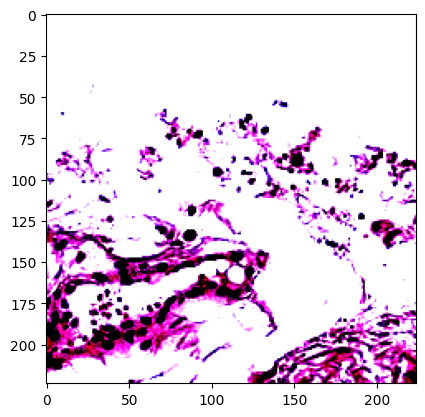

In [ ]:
# Show rotated image
mass_img, patient, img_name = dataset_rot270[0]
plt.imshow(mass_img.permute(1, 2, 0))

# Extract and save features

In [ ]:
# MODIFY

import os
import h5py
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm


# Specify filename and dataloader
HDF5_PATH = "uni2h_embeddings_rot270.hdf5"
dataloader = dataloader_rot270


# --- Feature Extraction & HDF5 Writing ---
with h5py.File(HDF5_PATH, 'w') as hdf5_file:
    for imgs, patient_ids, image_names in tqdm(dataloader, desc="UNI2‑h Feature Extraction"):
        imgs = imgs.to(device)
        with torch.no_grad():
            feats = model(imgs)  # shape: [B, 1536]
        feats = feats.cpu().numpy()

        for i in range(feats.shape[0]):
            grp = hdf5_file.require_group(f"{patient_ids[i]}")
            dname = os.path.splitext(image_names[i])[0]
            if dname in grp:
                continue  # skip if already exists
            grp.create_dataset(dname, data=feats[i], compression="gzip")

UNI2‑h Feature Extraction: 100%|██████████| 8074/8074 [12:18:53<00:00,  5.49s/it]


In [ ]:
!mv /content/uni2h_embeddings_rot270.hdf5 /content/drive/MyDrive/tcga_UNI2h_embeddings

In [ ]:
!du /content/drive/MyDrive/tcga_UNI2h_embeddings/* -hs

16G	/content/drive/MyDrive/tcga_UNI2h_embeddings/uni2h_embeddings_original.hdf5
16G	/content/drive/MyDrive/tcga_UNI2h_embeddings/uni2h_embeddings_rot180.hdf5
16G	/content/drive/MyDrive/tcga_UNI2h_embeddings/uni2h_embeddings_rot270.hdf5
16G	/content/drive/MyDrive/tcga_UNI2h_embeddings/uni2h_embeddings_rot90.hdf5
166M	/content/drive/MyDrive/tcga_UNI2h_embeddings/uni2h_index.faiss
20M	/content/drive/MyDrive/tcga_UNI2h_embeddings/uni2h_patch_metadata.parquet
